In [1]:
import html
import json
import re
import statistics
import unicodedata

import chromadb
import ftfy
import matplotlib.pyplot as plt
import numpy as np
from charset_normalizer import from_bytes
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter, CharacterTextSplitter, TextSplitter
from unstructured.cleaners.core import (
    clean,  # Удаляет лишние пробелы, пустые строки и нормализует текст
    # Исправляет битые кодировки (MIME / Quoted-Printable)
    # Соединяет случайно разорванные переносами строки
)

with open("filmoskop_kb.json", encoding="utf-8") as f:
    data = json.load(f)
docs = data["docs"]        # 181 раздел базы знаний
queries = data["queries"]  # 66 тестовых запросов с разметкой

print("Разделов:", len(docs), "| Запросов:", len(queries))

W1024 19:54:51.788000 8579 .venv/lib/python3.14/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Разделов: 181 | Запросов: 66


# Этап 1. Аудит и подготовка корпуса

In [2]:
MIN_LENGTH = 30          # Минимальная длина осмысленного документа
JUNK_THRESHOLD = 0.15    # Порог доли мусорных символов

def junk_ratio(text):
    if not text:
        return 0.0
    # Мусор: всё, что не буква, не цифра, не пробел
    # и не базовый знак препинания
    junk = re.findall(r"[^\w\s.,!?;:()«»—-]", text)
    return len(junk) / len(text)

def is_valid_text(raw_text: str) -> bool:
    stripped = raw_text.strip()
    if len(stripped) == 0:
        return False
    if len(stripped) < MIN_LENGTH:
        return False
    ratio = junk_ratio(stripped)
    if ratio > JUNK_THRESHOLD:
        return False
    return True


* Здесь и далее считаем, что "мусорным содержимым" текста является всё, что не буква, не цифра, не пробел.
* Корректным текстом для дальнейшей обработки и нормализации считаем тексты, у которых доля "мусора" не выше 0.15 и длина не меньше чем 30 символов.

Посчитаем среднюю долю "мусорного" содержимого в исходных текстах и долю корректных текстов.

In [3]:
mean_junk_ratio = np.mean([junk_ratio(doc["raw"]) for doc in docs])
valid_docs_share = sum(is_valid_text(doc["raw"]) for doc in docs) / len(docs)
print(f"Средняя доля мусорного содержимого в текстах набора: {mean_junk_ratio * 100:.2f}%")
print(f"Доля корректных документов в наборе: {valid_docs_share * 100:.2f}%")

Средняя доля мусорного содержимого в текстах набора: 3.43%
Доля корректных документов в наборе: 89.50%


Выведем тексты некорректных документов для понимания проблем

In [4]:
for doc in docs:
    if is_valid_text(doc["raw"]):
        continue
    print(f"Doc ID: {doc["doc_id"]}, length: {len(doc["raw"])}{"-" * 43}\n\t{doc["raw"][:60]}\n")

Doc ID: 22, length: 2961-------------------------------------------
	ÐÐ±Ð¾Ð·Ð½Ð°ÑÐµÐ½Ð¸Ðµ 5.1 Ð¾Ð¿Ð¸ÑÑÐ²Ð°ÐµÑ ÑÐ°ÑÐºÐ»Ð°Ð´

Doc ID: 38, length: 847-------------------------------------------
	ÐÐ±ÑÐµÐ´Ð¸Ð½Ð¸ÑÑ Ð´Ð²Ð° Ð°ÐºÐºÐ°ÑÐ½ÑÐ° Â«Ð¤Ð¸Ð»ÑÐ¼Ð¾Ñ

Doc ID: 43, length: 860-------------------------------------------
	Ð£ Ð¼Ð½Ð¾Ð³Ð¸Ñ ÑÐ¸Ð»ÑÐ¼Ð¾Ð² Ð¸ ÑÐµÑÐ¸Ð°Ð»Ð¾Ð² ÐµÑÑÑ 

Doc ID: 46, length: 604-------------------------------------------
	ÐÑÐ°ÑÐºÐ°Ñ Ð¿Ð°Ð¼ÑÑÐºÐ° Ð¿Ð¾ Ð¾ÑÐµÐ½ÐºÐ°Ð¼: ÑÑÐ°Ð²Ñ

Doc ID: 54, length: 683-------------------------------------------
	ÐÑÐ»Ð¸ Ð¿ÑÐ¸Ð»Ð¾Ð¶ÐµÐ½Ð¸Ðµ Ð·Ð°Ð²Ð¸ÑÐ°ÐµÑ Ð½Ð° Ð·Ð°ÑÑ

Doc ID: 55, length: 833-------------------------------------------
	ÐÑÐ»Ð¸ Ð½Ðµ Ð¿Ð¾Ð»ÑÑÐ°ÐµÑÑÑ Ð²Ð¾Ð¹ÑÐ¸, Ð½Ð°Ð¶Ð¼Ð¸ÑÐ

Doc ID: 60, length: 843-------------------------------------------
	ï»¿Ð¡ÑÐ°Ð±Ð¸Ð»ÑÐ½Ð¾ÑÑÑ Ð¿ÑÐ¾ÑÐ¼Ð¾ÑÑÐ° ÑÐ¸Ð»ÑÐ½Ð¾ 

Doc ID: 73, length: 3057-------------------------------------------
	# ÐÑÐµÐ½Ð´Ð° Ð¸ Ð¿

С первого взгляда можно сказать, что большая часть проблем связана с кодировкой текста. Есть просто слишком короткие тексты, не несущие никакой пользы (doc id: 153). Есть тексты, в которых осталась HTML разметка. Приступаем к фильтрации.

Для фильтрации будем использовать следующие библиотеки:

1. `ftfy`: для восстановления крякозябр
2. `unstructured`: для того чтобы иметь единый интерфейс для очистки текста
3. `unicodedata`: для нормализации


In [5]:
def smart_decode(raw_data) -> str:
    """
    Принимает на вход БАЙТЫ или СТРОКУ с неизвестной кодировкой
    и превращает в чистый читаемый текст.
    """
    if not raw_data:
        return ""

    # 1. Если пришли байты — определяем кодировку через charset-normalizer
    if isinstance(raw_data, bytes):
        match = from_bytes(raw_data).best()
        if match:
            text = str(match)
        else:
            # Фолбэк на случай неудачи
            text = raw_data.decode('utf-8', errors='ignore')
    else:
        text = raw_data

    # 2. Лечим «кракозябры» (можибэйк) с помощью ftfy.
    text = ftfy.fix_text(text)

    return text

def normalize_text(text):
    # Приводим юникод к единой форме NFC
    text = unicodedata.normalize("NFC", text)
    # Склеиваем слово, разорванное переносом строки
    text = re.sub(r"(\w)-\n(\w)", r"\1\2", text)
    # Неразрывные и нулевой ширины пробелы -> обычный пробел
    text = text.replace("\N{NO-BREAK SPACE}", " ")
    text = text.replace("\N{ZERO WIDTH SPACE}", " ")
    # Схлопываем подряд идущие пробелы и переносы в один пробел
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def clean_text_for_rag(raw_text: str) -> str:
    # Восстановление кодировок и сущностей
    text = smart_decode(raw_text)
    text = html.unescape(text)

    # Переводим HTML-теги разметки в переносы строк
    text = re.sub(r'<[^>]+>', '\n', text)

    # УДАЛЕНИЕ ВЕБ-МУСОРА
    # Удаляем хлебные крошки, только если они идут отдельной строкой
    text = re.sub(r'^\s*\w+\s*(?:→|->|>)\s*\w+.*$', '', text, flags=re.MULTILINE)
    # Удаляем Cookie
    text = re.sub(r'мы используем cookie[^.]+?\.\s*принять', ' ', text, flags=re.IGNORECASE)
    # Схлопываем дубли заголовков
    text = re.sub(r'\b([\w\s]{5,})\1\b', r'\1', text, flags=re.IGNORECASE)

    # ПОДГОТОВКА ДЛЯ RECURSIVE CHUNKING
    # Сохраняем четкие границы абзацев (\n\n), убирая избыточные пустые строки
    text = re.sub(r'\n{3,}', '\n\n', text)

    # Финальный unstructured и нормализация
    text = clean(text, dashes=True, bullets=True)
    text = normalize_text(text)

    return text

In [6]:
for doc in docs:
    doc["raw"] = clean_text_for_rag(doc["raw"])

mean_junk_ratio = np.mean([junk_ratio(doc["raw"]) for doc in docs])
valid_docs_share = sum(is_valid_text(doc["raw"]) for doc in docs) / len(docs)
print(f"Средняя доля мусорного содержимого в текстах набора: {mean_junk_ratio * 100:.2f}%")
print(f"Доля корректных документов в наборе: {valid_docs_share * 100:.2f}%")

Средняя доля мусорного содержимого в текстах набора: 0.21%
Доля корректных документов в наборе: 98.90%


* Средняя доля мусорного содержимого в текстах набора упала с `3.43%` до `0.21%`
* Доля корректных документов в наборе возросла с `89.50%` до `98.90%`


Посмотрим на оставшиеся некорректные документы

In [7]:
for doc in docs:
    if is_valid_text(doc["raw"]):
        continue
    print(f"Doc ID: {doc["doc_id"]}, length: {len(doc["raw"])}{"-" * 43}\n\t{doc["raw"][:60]}\n")

Doc ID: 153, length: 14-------------------------------------------
	QX 500;2020;да

Doc ID: 156, length: 14-------------------------------------------
	Схема разделов



Осталось только два документа длиной 14 символов. Содержимое этих документов не представляет ценности. Ими можно пренебречь.

Фильтруем выборку

In [8]:
docs = [doc for doc in docs if is_valid_text(doc["raw"])]

Проверяем отсутствие в наборе дублей.

In [9]:
print(f"Есть дубликаты по ID: {len(set([doc["doc_id"] for doc in docs])) != len(docs)}")
print(f"Есть дубликаты по тексту: {len(set([doc["raw"] for doc in docs])) != len(docs)}")

Есть дубликаты по ID: False
Есть дубликаты по тексту: False


Дублей в наборе нет

# Этап 2. Чанкинг и эмбеддинги

Нужно определить что из себя представляет содержимое текста. Для начала оценим статистические данные.

In [10]:
sizes = [len(doc["raw"]) for doc in docs]
min_text_size = min(sizes)
median_text_size = statistics.median(sizes)
max_text_size = max(sizes)
print(f"  текстов: {len(docs)}")
print(f"Статистика длины текстов\n  min / медиана / max: \n  {min_text_size} / {median_text_size:.0f} / {max_text_size}")

  текстов: 179
Статистика длины текстов
  min / медиана / max: 
  70 / 598 / 2004


Построим график

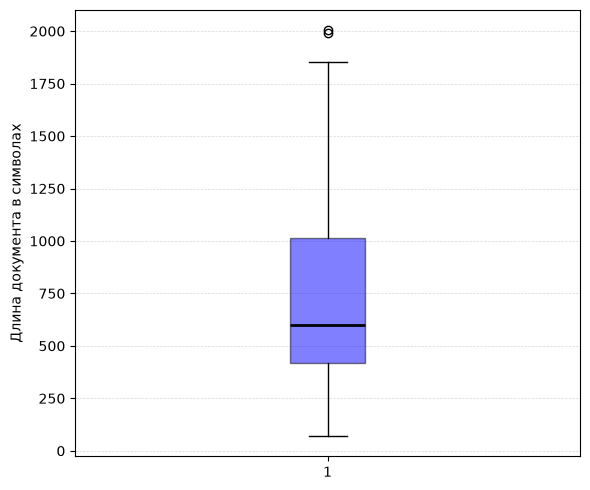

In [11]:
plt.figure(figsize=(6, 5))

# patch_artist=True позволяет раскрасить ящики
# medianprops настраивает линию медианы внутри ящика
box = plt.boxplot(sizes,
                  patch_artist=True,
                  medianprops={'color': 'black', 'linewidth': 2})

# Раскрашиваем ящики в разные цвета для наглядности
colors = ['blue']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)  # Делаем цвета приятнее с помощью прозрачности

plt.ylabel('Длина документа в символах')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Возьмём и рассмотрим (визуально) три примера: текст с минимальной длиной, средний текст (около медианы), и текст с максимальной длиной.

In [12]:
sample_min_doc = next((doc for doc in docs if len(doc["raw"]) == min_text_size), None)
sample_max_doc = next((doc for doc in docs if len(doc["raw"]) == max_text_size), None)
sample_med_doc = min(docs, key=lambda doc: abs(len(doc["raw"]) - median_text_size)) # Выбираем текст с наименьшей разницей в длине с медианой

In [13]:
for doc in [sample_min_doc, sample_med_doc, sample_max_doc]:
    print(f"Doc ID: {doc["doc_id"]}, title: `{doc["title"]}`, length: {len(doc["raw"])}, format: {doc["format"]}{"-" * 43}\n\t{doc["raw"]}\n")

Doc ID: 145, title: `Обновление приложения при ошибках`, length: 70, format: text-------------------------------------------
	Если ошибка мешает просмотру, обновите приложение до последней версии.

Doc ID: 86, title: `Поддерживаемые устройства`, length: 598, format: markdown-------------------------------------------
	# Поддерживаемые устройства На каких устройствах работает "Фильмоскоп" Телевизоры Smart TV: Samsung (Tizen, модели с 2018 года), LG (webOS 4.0 и новее), телевизоры и приставки на Android TV 9 и новее. ТВ приставки: Android TV, Apple TV (tvOS 15 и новее), приставки операторов партнеров. Телефоны и планшеты: iOS 15 и новее, Android 9 и новее. Компьютеры: браузеры Chrome, Firefox, Safari и Яндекс Браузер актуальных версий — без установки приложения. Игровые консоли: PlayStation 5 и Xbox Series. На устройствах вне этого списка работа приложения не гарантируется, даже если его удалось установить.

Doc ID: 173, title: `Что делать при подозрении на взлом`, length: 2004, format: 

Тексты похожи на статьи из базы знаний, но по какой-то одной конкретной теме. Попробуем начать с двух стратегий и применить:
1. Стратегия 1: рекурсивный чанкинг (сначала абзацы, потом точки, знаки ! и ?, потом пробелы) с overlap
2. Стратегия 2: посимвольный чанкинг по фиксированной длине с overlap.

Стратегию семантической нарезки отбрасываю как избыточную на этом наборе (наши тексты не очень длинные и все по отдельной теме).

В качестве эмбеддера будем использовать `intfloat/multilingual-e5-base`: рабочий выбор по умолчанию для русскоязычного RAG с хорошей размерностью.

Для нарезки выбираю значения `chunk_size=600` и `chunk_overlap=150`. Такой размер чанка гарантированно вместится в размерность нашего эмбеддинга (`768`) и позволит включить половину текстов полностью по одному чанку на каждый, а `chunk_overlap=150` позволит подстраховаться от разрывов в других чанках.


In [14]:
CHUNK_SIZE = 600
CHUNK_OVERLAP = 150

In [15]:
# Настраиваем чанкеры

# 1. Вариант: Умный рекурсивный
# Он идет по списку от \n\n (абзац) до "" (символ), пока не подгонит кусок под размер
recursive_splitter = RecursiveCharacterTextSplitter(
    separators=["\n\n", "\n", ". ", "! ", "? ", " ", ""],
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP
)

# 2. Вариант: Тупой посимвольный
# Указываем пустую строку в качестве separator, чтобы он игнорировал структуру
fixed_splitter = CharacterTextSplitter(
    separator="",
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    strip_whitespace=False # Чтобы не ломать индексы при жесткой нарезке
)

def get_langchain_docs(raw_docs: list[dict], splitter: TextSplitter) -> list[Document]:
    # 1. Сначала нарезаем документы как обычно
    docs = splitter.create_documents(
        texts=[doc["raw"] for doc in raw_docs],
        metadatas=[
            {
                "doc_id": doc["doc_id"],
                "title": doc["title"],
                "format": doc["format"],
                "category": doc["category"]
            }
            for doc in raw_docs
        ]
    )

    # 2. Проходимся по готовым чанкам и добавляем им сквозной уникальный chunk_id
    for chunk_idx, chunk in enumerate(docs):
        chunk.metadata["chunk_id"] = chunk_idx

    return docs

In [16]:
recursive_splitter_chunks = get_langchain_docs(docs, recursive_splitter)
fixed_splitter_chunks = get_langchain_docs(docs, fixed_splitter)

print("Количество документов: ", len(docs))
print("Количество чанков, созданных через рекурсивный чанкер:", len(recursive_splitter_chunks))
print("Количество чанков, созданных через посимвольный чанкер:", len(fixed_splitter_chunks))

Количество документов:  179
Количество чанков, созданных через рекурсивный чанкер: 318
Количество чанков, созданных через посимвольный чанкер: 325


## Подготовка пайплайна

Заранее подготовим классы и функции, которые мы будем использовать в нашем пайплайне.

In [17]:
from abc import ABC, abstractmethod
from typing import List, Dict, Set, Any, Tuple
from dataclasses import dataclass, field
import time

# =================================================================
# 1. БАЗОВЫЕ ОБЪЕКТЫ И МЕТРИКИ (Data Models)
# =================================================================

@dataclass
class RetrievedResult:
    """Результат поиска: документ, его оценка и ранг."""
    doc: Any
    score: float
    rank: int

class BaseRetriever(ABC):
    """Интерфейс, который мы будем использовать во всей системе."""
    @abstractmethod
    def retrieve(self, query: str, top_k: int) -> List[RetrievedResult]:
        pass

@dataclass
class SingleQueryMetrics:
    """
    Статистика по одному конкретному запросу.
    """
    query_data: Dict[str, Any]
    precision: float
    recall: float
    mrr: float
    max_precision: float  # Максимально возможный precision@top_k для этого запроса
    max_recall: float     # Максимально возможный recall@top_k для этого запроса
    retrieval_time: float

@dataclass
class DetailedTrace:
    """Детальный лог: что именно нашел ретривер."""
    query_data: Dict[str, Any]
    traces: List[Dict[str, Any]] = field(default_factory=list)

@dataclass
class GlobalSummary:
    """Агрегированные средние показатели по всему датасету."""
    total_queries: int
    top_k: int
    avg_precision: float
    avg_recall: float
    avg_mrr: float
    total_time: float
    avg_precision_delta: float # Средняя потеря точности (max_precision - precision)
    avg_recall_delta: float    # Средняя потеря полноты (max_recall - recall)

@dataclass
class RAGEvaluationReport:
    """Итоговый аналитический отчет."""
    summary: GlobalSummary
    detailed_traces: List[DetailedTrace]
    best_queries: List[SingleQueryMetrics]
    worst_queries: List[SingleQueryMetrics]

    def print_summary(self):
        s = self.summary
        print("\n" + "="*65)
        print(f" ОБЩИЙ ОТЧЕТ (N={s.total_queries}, top-k={s.top_k})")
        print("="*65)
        print(f" Средняя Точность (Precision): {s.avg_precision:.4f}")
        print(f" Средняя Полнота (Recall):    {s.avg_recall:.4f}")
        print(f" Средний MRR:                 {s.avg_mrr:.4f}")
        print(f" Общее время поиска:          {s.total_time:.2f} сек")
        print("-" * 65)
        print(f" Средняя дельта Precision:  {s.avg_precision_delta:.4f}")
        print(f" Средняя дельта Recall:     {s.avg_recall_delta:.4f}")
        print("="*65 + "\n")

        print("\n лучшие запросы (Max Recall):")
        for q in self.best_queries:
            print(f"[Recall: {q.recall:.2f}/{q.max_recall:.2f}] {q.query_data.get('query', '')}")

        print("-" * 65)

        print(" худшие запросы (Min Recall):")
        for q in self.worst_queries:
            print(f"[Recall: {q.recall:.2f}/{q.max_recall:.2f}] {q.query_data.get('query', '')}")
        print("="*65 + "\n")

    def print_detailed_traces(self):
        """Выводит подробную таблицу: Rank | Hit | Score | Text"""
        for dt in self.detailed_traces:
            query_text = dt.query_data.get('query', 'Unknown')
            print(f"\n запрос: {query_text}")
            print(f"{'Ранг':<5} | {'Релевантный':<4} | {'Score':<8} | {'Текст чанка'}")
            print("-" * 100)

            for t in dt.traces:
                # Метка Hit
                marker = "[+]" if t['is_relevant'] else "[-]"
                # Очистка текста от переносов строк для красоты
                clean_text = t['text'].replace('\n', ' ').strip()

                print(f"{t['rank']:<5} | {marker:<4} | {t['score']:<8.4f} | {clean_text}...")

            print("-" * 100)
        print("\n" + "═"*100 + "\n")

# =================================================================
# 2. МАТЕМАТИЧЕСКОЕ ЯДРО (Metrics & Math)
# =================================================================

def compute_retrieval_metrics_single(
    query_data: Dict[str, Any],
    retrieved_chunk_ids: List[int],  # ВАЖНО: Полный список всех ID из выдачи
    relevant_chunk_ids: Set[int],
    top_k: int
) -> SingleQueryMetrics:
    """
    Вычисляет метрики и находит теоретический максимум для данного запроса.
    """
    gold_set = set(int(x) for x in relevant_chunk_ids)
    total_relevant = len(gold_set)

    # Если релевантных документов нет, все метрики 0
    if total_relevant == 0:
        return SingleQueryMetrics(query_data=query_data,
                                  precision=0.0,
                                  recall=0.0,
                                  mrr=0.0,
                                  max_precision=0.0,
                                  max_recall=0.0,
                                  retrieval_time=0.0)

    hits = 0
    mrr = 0.0

    # 1. Считаем хиты и MRR по списку (сохраняя реальные ранги)
    for rank, c_id in enumerate(retrieved_chunk_ids, start=1):
        if c_id in gold_set:
            if hits == 0:
                mrr = 1.0 / rank
            hits += 1

    # 2. Текущие показатели
    # Precision@K = (количество найденных релевантных) / K
    precision = hits / top_k
    # Recall@K = (количество найденных релевантных) / (всего релевантных в базе)
    recall = hits / total_relevant

    # 3. Теоретические максимумы (что возможно получить при текущем top_k)
    # Максимальное кол-во хитов, которое мы можем получить:
    max_hits = min(top_k, total_relevant)

    max_prec = max_hits / top_k
    max_rec = max_hits / total_relevant

    return SingleQueryMetrics(
        query_data=query_data,
        precision=precision,
        recall=recall,
        mrr=mrr,
        max_precision=max_prec,
        max_recall=max_rec,
        retrieval_time=0.0
    )

# =================================================================
# 3. ДВИЖОК И АНАЛИТИК (Engine & Analyst)
# =================================================================

class DenseRetriever(BaseRetriever):
    def __init__(self, vector_store):
        self.vector_store = vector_store

    def retrieve(self, query: str, top_k: int) -> List[RetrievedResult]:
        query_text = normalize_text(query)
        docs_with_scores = self.vector_store.similarity_search_with_score(query_text, k=top_k)
        results = []
        for rank, (doc, score) in enumerate(docs_with_scores, start=1):
            results.append(RetrievedResult(doc=doc, score=score, rank=rank))
        return results

class RAGExperimentEngine:
    def __init__(self, retriever: BaseRetriever, queries: List[dict], ground_truth_map: Dict[int, Set[int]]):
        self.retriever = retriever
        self.queries = queries
        self.ground_truth_map = ground_truth_map
        self._prepared_queries = []

    def _prepare(self):
        self._prepared_queries = []
        for q in self.queries:
            rel_chunk_ids = set()
            for d_id in q.get("relevant_docs", []):
                rel_chunk_ids.update(self.ground_truth_map.get(int(d_id), set()))
            self._prepared_queries.append({
                "query_data": q,
                "relevant_chunks": rel_chunk_ids
            })

    def run(self, top_k: int) -> Tuple[List[Dict], List[Dict], float]:
        self._prepare()
        raw_metrics, raw_traces = [], []
        total_time = 0.0

        for q_item in self._prepared_queries:
            q_data = q_item["query_data"]
            rel_chunks = q_item["relevant_chunks"]

            start = time.perf_counter()
            results = self.retriever.retrieve(q_data["query"], top_k=top_k)
            duration = time.perf_counter() - start
            total_time += duration

            trace = {"query_data": q_data, "traces": []}
            all_retrieved_chunk_ids = [] # собираем ВСЕ ID из выдачи

            for rank, res in enumerate(results, start=1):
                chunk = res.doc
                c_id = chunk.metadata.get("chunk_id")
                d_id = chunk.metadata.get("doc_id")
                is_rel = c_id in rel_chunks

                all_retrieved_chunk_ids.append(c_id)

                trace["traces"].append({
                    "doc_id": d_id,
                    "chunk_id": c_id,
                    "is_relevant": is_rel,
                    "text": chunk.page_content[100:],
                    "score": res.score,
                    "rank": rank
                })

            # Передаем полный список для корректного расчета рангов (MRR)
            m = compute_retrieval_metrics_single(q_data, all_retrieved_chunk_ids, rel_chunks, top_k)
            m.retrieval_time = duration
            raw_metrics.append(m.__dict__)
            raw_traces.append(trace)

        return raw_metrics, raw_traces, total_time

class RAGAnalyzer:
    @staticmethod
    def analyze(top_k: int, raw_metrics: List[Dict], raw_traces: List[Dict], total_time: float) -> RAGEvaluationReport:
        count = len(raw_metrics)
        if count == 0:
            return RAGEvaluationReport(GlobalSummary(0, top_k, 0, 0, 0, 0, 0, 0), [], [], [])

        avg_prec = sum(m["precision"] for m in raw_metrics) / count
        avg_rec = sum(m["recall"] for m in raw_metrics) / count
        avg_mrr = sum(m["mrr"] for m in raw_metrics) / count

        # Дельта = (Максимум, который мог быть) - (Что получили по факту)
        avg_p_delta = sum(m["max_precision"] - m["precision"] for m in raw_metrics) / count
        avg_r_delta = sum(m["max_recall"] - m["recall"] for m in raw_metrics) / count

        sorted_by_recall = sorted(raw_metrics, key=lambda x: x["recall"], reverse=True)

        summary = GlobalSummary(
            total_queries=count,
            top_k=top_k,
            avg_precision=avg_prec,
            avg_recall=avg_rec,
            avg_mrr=avg_mrr,
            total_time=total_time,
            avg_precision_delta=avg_p_delta,
            avg_recall_delta=avg_r_delta
        )

        return RAGEvaluationReport(
            summary=summary,
            detailed_traces=[DetailedTrace(t['query_data'], t['traces']) for t in raw_traces],
            best_queries=[SingleQueryMetrics(**m) for m in sorted_by_recall[:3]],
            worst_queries=[SingleQueryMetrics(**m) for m in sorted_by_recall[-3:][::-1]]
        )

In [18]:
def build_ground_truth_map(chunks: List[Document]) -> Dict[int, Set[int]]:
    """
    Создает карту соответствия: doc_id -> {set of chunk_ids}.
    Вызывается один раз перед каждым новым экспериментом,
    поскольку при изменении стратегии чанкинга ID чанков меняются.
    """
    gt_map = {}
    for chunk in chunks:
        # Берем метаданные, которые мы гарантированно заложили при чанкинге
        doc_id = chunk.metadata.get("doc_id")
        chunk_id = chunk.metadata.get("chunk_id")

        if doc_id is not None and chunk_id is not None:
            # Преобразуем в int, на случай если метаданные пришли строками
            d_id = int(doc_id)
            c_id = int(chunk_id)

            if d_id not in gt_map:
                gt_map[d_id] = set()
            gt_map[d_id].add(c_id)

    return gt_map

In [19]:
from chromadb import Settings

def create_clean_vectorstore(chunks, embedding_model, collection_name: str):
    """
    Создает и возвращает абсолютно чистую базу данных Chroma в оперативной памяти
    с заданным именем коллекции. Предотвращает смешивание данных.
    """
    # 1. Создаем эфемерный клиент Chroma (живет только в ОЗУ)
    chroma_client = chromadb.EphemeralClient()

    # 2. Инициализируем vectorstore с указанием клиента и имени коллекции
    vectorstore = Chroma.from_documents(
        documents=chunks,
        embedding=embedding_model,
        client=chroma_client,
        collection_name=collection_name,
        client_settings=Settings(
            chroma_api_impl="chromadb.api.segment.SegmentAPI",
            is_persistent=False  # Явно указываем, что сохранять на диск не нужно
        ),
        collection_metadata={"hnsw:space": "cosine"} # косинус задаём явно
    )

    return vectorstore

### Загружаем эмбеддинги

In [20]:
embeddings = HuggingFaceEmbeddings(
    model_name="intfloat/multilingual-e5-base",
    model_kwargs={"device": "mps"},
    encode_kwargs={"normalize_embeddings": True, "prompt": "passage: "},
    query_encode_kwargs={"normalize_embeddings": True, "prompt": "query: "},
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

## Замер метрик retrieval по стратегии 1 (рекурсивный чанкинг)

### Создаём векторное хранилище

In [21]:
recursive_chunks_vector_store = create_clean_vectorstore(recursive_splitter_chunks, embeddings, "col_1")

Создаём удобную карту соответствия для чанков, нарезанных рекурсивным способом

In [22]:
gt_map_rec = build_ground_truth_map(recursive_splitter_chunks)

Считаем метрики (исключаем `gap` запросы). Попробуем запустить на значениях `top_k` (5, 10, 20, 30) и отследить тенденцию.

In [23]:
retriever_rec = DenseRetriever(vector_store=recursive_chunks_vector_store)
engine_rec = RAGExperimentEngine(retriever_rec, [query for query in queries if query["kind"] != "gap"], gt_map_rec)
for k in (5, 10, 20, 30):
    raw_m_rec, raw_t_rec, time_rec = engine_rec.run(top_k=k)
    report_rec = RAGAnalyzer.analyze(top_k=k, raw_metrics=raw_m_rec, raw_traces=raw_t_rec, total_time=time_rec)
    report_rec.print_summary()


 ОБЩИЙ ОТЧЕТ (N=56, top-k=5)
 Средняя Точность (Precision): 0.2464
 Средняя Полнота (Recall):    0.4030
 Средний MRR:                 0.5107
 Общее время поиска:          0.43 сек
-----------------------------------------------------------------
 Средняя дельта Precision:  0.3750
 Средняя дельта Recall:     0.5301


 лучшие запросы (Max Recall):
[Recall: 1.00/1.00] какая версия webOS или Tizen нужна для приложения на телевизоре
[Recall: 1.00/1.00] какая скорость интернета нужна для 4K
[Recall: 1.00/1.00] есть ли приложение Фильмоскопа для Nintendo Switch
-----------------------------------------------------------------
 худшие запросы (Min Recall):
[Recall: 0.00/0.62] заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код
[Recall: 0.00/1.00] где менять картинку — в приложении или в самом телевизоре
[Recall: 0.00/1.00] в приложении всё включено, а на телефон ничего не приходит


 ОБЩИЙ ОТЧЕТ (N=56, top-k=10)
 Средняя Точность (Precision): 0.1714
 Средняя Полнота

| Значение K | Средний Precision | Средний Delta Precision | Средний Recall | Средний Delta Recall | Средний MRR |
|-----------:|:-----------------:|:-----------------------:|:--------------:|:--------------------:|:-----------:|
|          5 |      0.2464       |         0.3750          |     0.4030     |        0.5301        |   0.5107    |
|         10 |      0.1714       |         0.1893          |     0.4939     |        0.5061        |   0.5157    |
|         20 |      0.1188       |         0.0616          |     0.6824     |        0.3176        |   0.5229    |
|         30 |      0.0946       |         0.0256          |     0.8136     |        0.1864        |   0.5250    |

Можно увидеть, что при повышении top_k заметно снижается расстояние до "потолка" по precision и recall. А вот значения MRR не растут.

Мои ключевые выводы:
1. Информационная емкость чанков отличная. С ростом K с 5 до 30 recall вырастает более чем в два раза, а Средний Delta Recall падает с 0.53 до 0.18.
2. Тот факт, что при (K=30) Recall вырос до 81%, а MRR практически не изменился, говорит о следующем: для тех запросов, которые система умеет находить хорошо, первый чанк всегда лежит в самом верху (на 2-м месте). А те чанки, которые добираются при увеличении (K) до 30 (давая прирост к Recall), оседают глубоко на дне выдачи (на 15-30 местах) и никак не влияют на MRR

## Замер метрик retrieval по стратегии 2 (посимвольный чанкинг по фиксированной длине с overlap)

In [24]:
fixed_chars_chunks_vector_store = create_clean_vectorstore(fixed_splitter_chunks, embeddings, "col_2")

Создаём удобную карту соответствия для чанков, нарезанных посимвольным фиксированным способом

In [25]:
gt_map_char_fixed = build_ground_truth_map(fixed_splitter_chunks)

Считаем метрики (исключаем `gap` запросы). Попробуем запустить на значениях `top_k` (5, 10, 20, 30) и отследить тенденцию.

In [26]:
retriever_fixed_char = DenseRetriever(vector_store=fixed_chars_chunks_vector_store)
engine_fixed_char = RAGExperimentEngine(retriever_fixed_char, [query for query in queries if query["kind"] != "gap"], gt_map_char_fixed)
for k in (5, 10, 20, 30):
    raw_m_fixed_char, raw_t_fixed_char, time_fixed_char = engine_fixed_char.run(top_k=k)
    report_fixed_char = RAGAnalyzer.analyze(top_k=k, raw_metrics=raw_m_fixed_char, raw_traces=raw_t_fixed_char, total_time=time_fixed_char)
    report_fixed_char.print_summary()


 ОБЩИЙ ОТЧЕТ (N=56, top-k=5)
 Средняя Точность (Precision): 0.2214
 Средняя Полнота (Recall):    0.3728
 Средний MRR:                 0.4917
 Общее время поиска:          0.41 сек
-----------------------------------------------------------------
 Средняя дельта Precision:  0.4107
 Средняя дельта Recall:     0.5528


 лучшие запросы (Max Recall):
[Recall: 1.00/1.00] какая версия webOS или Tizen нужна для приложения на телевизоре
[Recall: 1.00/1.00] есть ли приложение Фильмоскопа для Nintendo Switch
[Recall: 1.00/1.00] поддерживается ли телевизор QX-450
-----------------------------------------------------------------
 худшие запросы (Min Recall):
[Recall: 0.00/0.62] заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код
[Recall: 0.00/0.83] хочу смотреть в 4K — какой нужен тариф и какая скорость интернета
[Recall: 0.00/0.62] сколько стоит самый дешёвый тариф и можно ли на нём скачивать фильмы


 ОБЩИЙ ОТЧЕТ (N=56, top-k=10)
 Средняя Точность (Precision): 0.1607
 

| Значение K | Средний Precision | Средний Delta Precision | Средний Recall | Средний Delta Recall | Средний MRR |
|:----------:|:-----------------:|:-----------------------:|:--------------:|:--------------------:|:-----------:|
|     5      |      0.2214       |         0.4107          |     0.3728     |        0.5528        |   0.4917    |
|     10     |      0.1607       |         0.2107          |     0.4824     |        0.5176        |   0.5092    |
|     20     |      0.1152       |         0.0705          |     0.6576     |        0.3424        |   0.5123    |
|     30     |      0.0905       |         0.0333          |     0.7631     |        0.2349        |   0.5139    |

Поскольку посимвольный чанкер иногда "режет" слова по середине, надо понимать, сколько чанков были обрезаны в середине слова. Для этого воспользуемся функцией.

In [27]:
def show_word_splits(chunks, max_to_show=3):
    """
    Простая функция для поиска разрывов слов между соседними чанками.
    """
    splits_count = 0

    # Идем циклом по всем чанкам, сравнивая текущий (i) и следующий (i + 1)
    for i in range(len(chunks) - 1):
        chunk1 = chunks[i]
        chunk2 = chunks[i + 1]

        # Проверяем, что оба чанка принадлежат одному и тому же исходному документу
        if chunk1.metadata.get("doc_id") == chunk2.metadata.get("doc_id"):

            text1 = chunk1.page_content.strip()
            text2 = chunk2.page_content.strip()

            # Если тексты не пустые, берем символы на стыке
            if text1 and text2:
                last_char = text1[-1]
                first_char = text2[0]

                # Если оба символа являются буквами или цифрами это разрыв слова
                if last_char.isalnum() and first_char.isalnum():
                    splits_count += 1

                    # Выводим первые несколько примеров на экран
                    if splits_count <= max_to_show:
                        print(f"Разрыв между чанками {i} и {i+1} (Doc ID: {chunk1.metadata.get('doc_id')})")
                        print(f"Конец чанка {i}:   ...{text1[-25:]}")
                        print(f"Начало чанка {i+1}:  {text2[:25]}...")
                        print("-" * 50)

    print(f"Всего найдено разрывов слов: {splits_count}")

In [28]:
show_word_splits(recursive_splitter_chunks)

Всего найдено разрывов слов: 0


In [29]:
show_word_splits(fixed_splitter_chunks)

Разрыв между чанками 1 и 2 (Doc ID: 1)
Конец чанка 1:   ...левизоре. При этом у кажд
Начало чанка 2:  ойки самого профиля — язы...
--------------------------------------------------
Разрыв между чанками 2 и 3 (Doc ID: 1)
Конец чанка 2:   ...ных устройствах могут рас
Начало чанка 3:  требует интернета. Если у...
--------------------------------------------------
Разрыв между чанками 5 и 6 (Doc ID: 3)
Конец чанка 5:   ...ым без ограничений по вре
Начало чанка 6:  нно: премьеры и новые сез...
--------------------------------------------------
Всего найдено разрывов слов: 133


#### Анализ результатов

На тестовом датасете были сравнены два подхода к нарезке при идентичных параметрах (`chunk_size=600`, `chunk_overlap=150`). Оба алгоритма выдали практически одинаковую плотность разбиения, что делает сравнение математически точным.


##### Анализ метрик плотного поиска
На всех значениях `top-k` рекурсивный чанкер показывает больший recall, и меньший "потолок" до максимального recall и precision.

##### Анализ разрывов чанков
Ожидаемо мы не увидели ни единого разрыва в середине слова от рекурсивного чанкера, в то время как фиксированный чанкер сделал `133` разрыва. Это очень много. Потенциально мысль может быть потеряна, даже с учётом последующего реранкинга (ведь может быть утеряно подлежащее в предложении).

## Выводы и решение
Для RAG-системы мы выбираем рекурсивный чанкер по следующим причинам:
1. Сохранение синтаксической целостности: ппосимвольный чанкер жестко режет текст ровно на 600-м символе, разрывая слова, предложения и логические абзацы на полуслове. При передаче такого контекста в модель резко возрастает риск галлюцинаций и падения качества ответов, так как модель получает рваный текст. Рекурсивный чанкер бережно режет по границам предложений и пробелам.
2. Более высокие показатели `recall` при равных top-k. Меньший зазор до "потолка" по `recall`, `precision`.

Итоговое решение: выбираем рекурсивный чанкер. Он обеспечивает высокое качество исходного текста для генерации ответов.

# Этап 3. Поисковая инфраструктура и retrieval-пайплайн

## Выбор хранилища векторов

Выбор хранилища векторов предлагаю остановить на Chroma. Это золотая середина для нашего прототипа, поскольку более простой FAISS не поддерживает метаданные и поиск по ним. У нас в исходных данных есть много полезных метаданных (`title`, `category`, `format`), по которым можно потенциально фильтровать выборку. Потребности в более сложном Quadrant у нас нет: поскольку это прототип, нам не требуется масштабирование на кластер.

## Настройка индекса

У нас менее 500 чанков, поэтому можно было бы для прототипа смело взять `IndexFlat`, **но** Chroma использует `HNSW` и не даёт API для настройки типа индексации, поэтому будем использовать HNSW. Поскольку данных у нас немного, мы можем поднять значения параметров конфигурации индекса чтобы он искал более эффективно и не сильно влиял на наши измерения recall.

In [30]:
chroma_client = chromadb.EphemeralClient()

# Настраиваем метаданные HNSW графа для максимальной точности
hnsw_config = {
    "hnsw:space": "cosine",       # Метрика расстояния
    "hnsw:search_ef": 250,        # Глубина поиска (по умолчанию 100). Выше = точнее.
    "hnsw:construction_ef": 200,  # Глубина построения графа (по умолчанию 100).
}

main_vector_store = Chroma.from_documents(
    documents=recursive_splitter_chunks, # ранее составленные документы по рекурсивной стратегии нарезки
    embedding=embeddings, # Эмбеддинги мы загрузили ранее
    client=chroma_client,
    collection_name="main_vector_store",
    collection_metadata=hnsw_config
)

Теперь надо определить границу отсечения. Для этого надо наглядно увидеть в диапазоне каких значений лежат оценки найденных релевантных чанков

Подготовим данные на всех вопросах (кроме gap) и соберём в две группы (релевантные/нерелевантные) полученные оценки на `top-k=30` (чтобы увидеть побольше данных)

Сначала для удобства подготовим функцию, которая будет определять, является ли чанк релевантным запросу

In [31]:
def is_chunk_relevant_to_query(doc_chunk: Document, query_item: dict) -> bool:
    doc_id = doc_chunk.metadata.get("doc_id")
    if doc_id is None:
        return False
    relevant_doc_ids = query_item["relevant_docs"]
    if relevant_doc_ids is None:
        return False
    return doc_id in relevant_doc_ids

In [32]:
relevant_dist_scores = []
irrelevant_dist_scores = []

dense_retriever = DenseRetriever(vector_store=main_vector_store)
for query in queries:
    if query["kind"] == "gap":
        continue
    query_text = normalize_text(query["query"])
    retrieved_results = dense_retriever.retrieve(query_text, top_k=30)
    for res in retrieved_results:
        if is_chunk_relevant_to_query(res.doc, query):
            relevant_dist_scores.append(res.score)
        else:
            irrelevant_dist_scores.append(res.score)

Строим график

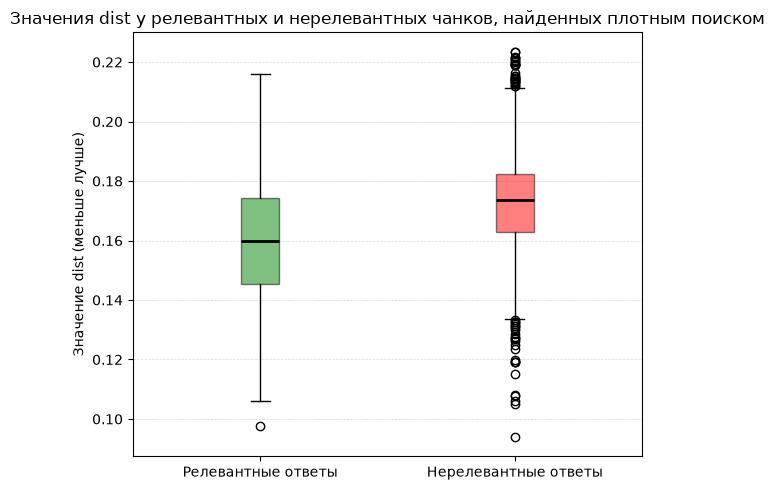

In [33]:
plt.figure(figsize=(6, 5))

# patch_artist=True позволяет раскрасить ящики
# medianprops настраивает линию медианы внутри ящика
box = plt.boxplot([relevant_dist_scores, irrelevant_dist_scores],
                  tick_labels=['Релевантные ответы', 'Нерелевантные ответы'],
                  patch_artist=True,
                  medianprops={'color': 'black', 'linewidth': 2})

# Раскрашиваем ящики в разные цвета для наглядности
colors = ['green', 'red']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)  # Делаем цвета приятнее с помощью прозрачности

plt.title('Значения dist у релевантных и нерелевантных чанков, найденных плотным поиском')
plt.ylabel('Значение dist (меньше лучше)')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


По графику видно, что есть много выбросов, где нерелевантные ответы получили близкую оценку dist. Думаю, что это будет устранено позже с помощью реранкера. Если взять порог отсечения `dist<=0.16`, тогда мы забираем больше половины релевантных ответов и отсекаем нижнюю квартиль нерелевантных ответов, что очень хорошо. Думаю, что это вполне рабочее значение.

### Проверка фильтрации по метаданным

Создаём класс-обёртку для возможности фильтрации по метаданным

In [34]:
class MetadataFilteredDenseRetriever(BaseRetriever):
    """
    Класс-обёртка над DenseRetriever, который добавляет возможность
    фильтрации результатов по метаданным.
    """
    def __init__(self, retriever: DenseRetriever, metadata_filter: Dict[str, Any]):
        """
        :param retriever: Экземпляр DenseRetriever, который мы оборачиваем.
        :param metadata_filter: Словарь с правилами фильтрации (например, {"user_id": 123, "type": "doc"}).
        """
        self.base_retriever = retriever
        self.metadata_filter = metadata_filter

    def retrieve(self, query: str, top_k: int) -> List[RetrievedResult]:
        query_text = normalize_text(query)
        docs_with_scores = self.base_retriever.vector_store.similarity_search_with_score(
            query_text,
            k=top_k,
            filter=self.metadata_filter
        )
        results = []
        for rank, (doc, score) in enumerate(docs_with_scores, start=1):
            results.append(RetrievedResult(doc=doc, score=score, rank=rank))

        return results

In [35]:
test_query_text = "что делать если забыл пароль"

filtered_retriever = MetadataFilteredDenseRetriever(retriever=dense_retriever, metadata_filter={"category": "Аккаунт и профили"})

# Запрос с фильтром по категории "Аккаунт и профили"
print("Запрос с фильтром по категории Аккаунт и профили")
for res in filtered_retriever.retrieve(query=test_query_text, top_k=10):
    chunk = res.doc
    doc_id = chunk.metadata.get("doc_id")
    title = chunk.metadata.get("title")
    category = chunk.metadata.get("category")
    print(f"\tDoc: id={doc_id}, \tcategory={category}, \ttitle={title}")


# Запрос без фильтра
print("Запрос без фильтра")
for res in dense_retriever.retrieve(query=test_query_text, top_k=10):
    chunk = res.doc
    doc_id = chunk.metadata.get("doc_id")
    title = chunk.metadata.get("title")
    category = chunk.metadata.get("category")
    print(f"\tDoc: id={doc_id}, \tcategory={category}, \ttitle={title}")


Запрос с фильтром по категории Аккаунт и профили
	Doc: id=173, 	category=Аккаунт и профили, 	title=Что делать при подозрении на взлом
	Doc: id=55, 	category=Аккаунт и профили, 	title=Восстановление пароля
	Doc: id=173, 	category=Аккаунт и профили, 	title=Что делать при подозрении на взлом
	Doc: id=169, 	category=Аккаунт и профили, 	title=Восстановление пароля (архив)
	Doc: id=173, 	category=Аккаунт и профили, 	title=Что делать при подозрении на взлом
	Doc: id=72, 	category=Аккаунт и профили, 	title=Почему не удаётся войти в аккаунт
	Doc: id=2, 	category=Аккаунт и профили, 	title=Безопасность аккаунта: общие советы
	Doc: id=84, 	category=Аккаунт и профили, 	title=ПИН-код (архив)
	Doc: id=72, 	category=Аккаунт и профили, 	title=Почему не удаётся войти в аккаунт
	Doc: id=9, 	category=Аккаунт и профили, 	title=Выход со всех устройств
Запрос без фильтра
	Doc: id=173, 	category=Аккаунт и профили, 	title=Что делать при подозрении на взлом
	Doc: id=55, 	category=Аккаунт и профили, 	title=Восст

Видим, что даже без фильтра, плотный поиск довольно хорошо находит нужную категорию, без её явного указания, но запрос без фильтров (второй) привёл к появлению выбросов из других категорий.

### baseline-метрики на запросах с ответом в базе

_Для подсчёта baseline метрик можно воспользоваться классами и функциями, которые мы использовали для выбора стратегии чанкинга. В этих функциях уже реализован подсчёт метрик следующим образом: поскольку мы работаем с чанками, а не документами, то `recall` в моём случае считается как отношение количества найденных релевантных чанков к количеству всех релевантных чанков (даже тех, которые не попали в `top-k`). Это делает метрику более точной: чанк считается релевантным, если относится к документу, помеченному как релевантный для данного запроса. При этом основную информацию будет давать не значение само по себе, а его дельта до его максимальных значений на этом `k`_

In [36]:
dense_retriever = DenseRetriever(vector_store=main_vector_store)
dense_retriever_experiment_engine = RAGExperimentEngine(dense_retriever, [query for query in queries if query["kind"] != "gap"], gt_map_rec)
for k in (1, 3, 5, 10, 20):
    raw_m_rec, raw_t_rec, time_rec = dense_retriever_experiment_engine.run(top_k=k)
    report_rec = RAGAnalyzer.analyze(top_k=k, raw_metrics=raw_m_rec, raw_traces=raw_t_rec, total_time=time_rec)
    report_rec.print_summary()


 ОБЩИЙ ОТЧЕТ (N=56, top-k=1)
 Средняя Точность (Precision): 0.3393
 Средняя Полнота (Recall):    0.1433
 Средний MRR:                 0.3393
 Общее время поиска:          0.44 сек
-----------------------------------------------------------------
 Средняя дельта Precision:  0.6607
 Средняя дельта Recall:     0.3192


 лучшие запросы (Max Recall):
[Recall: 1.00/1.00] какая версия webOS или Tizen нужна для приложения на телевизоре
[Recall: 1.00/1.00] есть ли приложение Фильмоскопа для Nintendo Switch
[Recall: 1.00/1.00] телевизор показывает чёрный экран, но звук идёт
-----------------------------------------------------------------
 худшие запросы (Min Recall):
[Recall: 0.00/0.33] у меня телевизор AM-9, приложение не ставится — как тогда смотреть
[Recall: 0.00/0.12] заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код
[Recall: 0.00/0.17] хочу смотреть в 4K — какой нужен тариф и какая скорость интернета


 ОБЩИЙ ОТЧЕТ (N=56, top-k=3)
 Средняя Точность (Precision)

Запишем результаты:
| Значение K | Средний Precision | Средний Delta Precision | Средний Recall | Средний Delta Recall | Средний MRR |
|:----------:|:-----------------:|:-----------------------:|:--------------:|:--------------------:|:-----------:|
|     1      |      0.3393       |         0.6607          |     0.1433    |        0.3192        |   0.3393    |
|     3      |      0.2917       |         0.4762         |     0.3185     |        0.4709       |   0.4911    |
|     5      |      0.2464       |         0.3750          |     0.4030     |        0.5301        |   0.5107    |
|     10     |      0.1714       |         0.1893          |     0.4939     |        0.5061        |   0.5157    |
|     20     |      0.1188       |         0.0616         |     0.6824    |        0.3176        |   0.5229    |

# Диагностика и улучшение retrieval

Ожидаемо `recall` растет при увеличении `top-k`, а `precision` падает. Абсолютные значения `precision` ничего не значат, ведь зазор до потолка по `precision` очень сильно снизился при `top-k=20`. Видим, что `recall` прилично растёт, но зазор до потолка остаётся высоким. По среднему `MRR` видим, что в среднем релевантные запросы попадают на вторую позицию. `MRR` сможем поднять через реранкер, а `recall` через гибридный поиск или оптимизацию запроса.

Рассмотрим запросы с низкими метриками recall на `top-k=30`

In [37]:
raw_m_rec, raw_t_rec, time_rec = dense_retriever_experiment_engine.run(top_k=30)
report_rec = RAGAnalyzer.analyze(top_k=30, raw_metrics=raw_m_rec, raw_traces=raw_t_rec, total_time=time_rec)
report_rec.print_summary()


 ОБЩИЙ ОТЧЕТ (N=56, top-k=30)
 Средняя Точность (Precision): 0.0946
 Средняя Полнота (Recall):    0.8136
 Средний MRR:                 0.5250
 Общее время поиска:          0.46 сек
-----------------------------------------------------------------
 Средняя дельта Precision:  0.0256
 Средняя дельта Recall:     0.1864


 лучшие запросы (Max Recall):
[Recall: 1.00/1.00] какая версия webOS или Tizen нужна для приложения на телевизоре
[Recall: 1.00/1.00] обязателен ли HDCP 2.2 для просмотра в 4K
[Recall: 1.00/1.00] что означает ошибка P-109
-----------------------------------------------------------------
 худшие запросы (Min Recall):
[Recall: 0.00/1.00] в приложении всё включено, а на телефон ничего не приходит
[Recall: 0.00/1.00] начал в метро с телефона, дома хочу досмотреть на большом экране с той же секунды
[Recall: 0.25/1.00] заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код



In [38]:
bad_query1 = next((q for q in queries if q["query"].startswith("в приложении всё включено, а на телефон ничего не приходит")), None)
bad_query2 = next((q for q in queries if q["query"].startswith("начал в метро с телефона, дома хочу досмотреть на большом эк")), None)
bad_query3 = next((q for q in queries if q["query"].startswith("заплатил за новинку отдельно — сколько она у меня будет и за")), None)

Посмотрим худшие запросы детально

In [39]:
dense_retriever_problem_queries_engine = RAGExperimentEngine(dense_retriever, [bad_query1, bad_query2, bad_query3], gt_map_rec)
raw_m_rec, raw_t_rec, time_rec = dense_retriever_problem_queries_engine.run(top_k=30)
report_rec = RAGAnalyzer.analyze(top_k=30, raw_metrics=raw_m_rec, raw_traces=raw_t_rec, total_time=time_rec)
report_rec.print_detailed_traces()


 запрос: в приложении всё включено, а на телефон ничего не приходит
Ранг  | Релевантный | Score    | Текст чанка
----------------------------------------------------------------------------------------------------
1     | [-]  | 0.1514   | ь. Браузер или менеджер паролей подставляет старое значение, если пароль меняли на другом устройстве. Введите его вручную, а не выбором из списка. Старая версия приложения. На телевизорах и приставках обновления иногда не ставятся сами, и в старой сборке экран входа может не открыться или зависнуть на загрузке. Помогает обновление приложения из магазина устройства. Если пароль не подходит ни в одном варианте, дело уже не в опечатке — порядок восстановления описан в отдельном разделе справки....
2     | [-]  | 0.1544   | мер, а код вводится там же, где вы начали вход. Ранее выполненный вход — самый частый случай. На устройстве, где вход уже сделан, приложение открывается сразу на экране выбора профиля и ничего не спрашивает. Так продолжается до тех п

Во всех трех случаях пользователи пишут своими словами, описывая некий сценарий, а база знаний хранит сухие, емкие ответы инструкции. Для таких задач query expansion на ключевых словах практически бесполезен, так как пересечение по токенам (словам) между вопросом и ответом близко к нулю. Реранкер не решит те проблемные кейсы, где recall оказался нулевым, поскольку значение 0.00 указывает на то, что нужные чанки вообще не попали в выборку. Но при этом (судя по средним значениям MRR) у нас релевантный чанк чаще всего занимает второе место. В одном из проблемных запросов один релевантные чанки всё же были найдены, но попали вниз выдачи.

Мой вердикт:

1. **реранкер cross-encoder**: рассмотреть для поднятия релевантных чанков в выдаче
2. **query expansion**: не поможет, так как проблемные запросы не используют специфических терминов. Скорее всего только снизит recall.
3. **HyDE**: рассмотреть для поднятия recall, так как проблемные запросы написаны живым языком и вообще зачастую имеют непонятное намерение пользователя.
4. **гибридный поиск с BM25**: не вижу необходимости, поскольку эмбеддер достаточно хороший и запросы, содержащие конкретые "якоря" вроде кодов ошибок или названия технологий, и так оказываются в топе выдачи. Хотя, это конечно может стать проблемой в будущем, когда появятся новые коды ошибок. В таком случае плотный поиск будет "склеивать" семантически их.
5. **слияние результатов через RRF**: рассмотреть для применения вместе с HyDE


## Cross encoder и reranker

Сначала попытаемся поднять средний MRR. Вводим Reranking (Cross-Encoder). Cross encoder добавляется в самый конец нашей цепочки декораторов.

In [40]:
from sentence_transformers import CrossEncoder

cross_encoder_reranker_model = CrossEncoder("BAAI/bge-reranker-v2-m3", device="mps")

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

In [41]:
class RerankedRetriever(BaseRetriever):
    def __init__(
        self,
        base_retriever: BaseRetriever,
        cross_encoder: CrossEncoder,
        rerank_k: int = 30
    ):
        """
        :param base_retriever: Базовый retriever
        :param cross_encoder: Уже инициализированный объект CrossEncoder
        :param rerank_k: Сколько документов запросить у базового retriever для переранжирования
        """
        self.base_retriever = base_retriever
        self.cross_encoder = cross_encoder
        self.rerank_k = rerank_k

    def retrieve(self, query: str, top_k: int = 5) -> List[RetrievedResult]:
        query = normalize_text(query)
        initial_results = self.base_retriever.retrieve(query, top_k=self.rerank_k) # Получаем широкий набор документов (Bi-Encoder)

        if not initial_results:
            return []

        # Подготовка пар (query, text)
        pairs = [[query, res.doc.page_content] for res in initial_results]

        # Вычисление скоров
        rerank_scores = self.cross_encoder.predict(pairs, batch_size=8, show_progress_bar=False)

        # 4. Сборка результатов
        reranked_results = []
        for i, score in enumerate(rerank_scores):
            reranked_results.append(RetrievedResult(
                doc=initial_results[i].doc,
                score=float(score),
                rank=i + 1
            ))

        # 5. Сортировка и обрезка
        reranked_results.sort(key=lambda x: x.score, reverse=True)
        return reranked_results[:top_k]

In [42]:
# 1. Настройка ретриверов
dense_retriever = DenseRetriever(vector_store=main_vector_store)

rerank_retriever = RerankedRetriever(
    base_retriever=dense_retriever,
    cross_encoder=cross_encoder_reranker_model,
    rerank_k=30  # мы даем реранкеру 30 кандидатов, чтобы он вытащил лучших
)

TOP_K = 5 # Фиксируем значение для эксперимента

# 2. Запуск эксперимента для Baseline (Bi-Encoder)
# Мы сравниваем только то, что попадает в финальный топ-5
engine_baseline = RAGExperimentEngine(
    dense_retriever,
    [q for q in queries if q["kind"] != "gap"],
    gt_map_rec
)
raw_m_base, raw_t_base, time_base = engine_baseline.run(top_k=TOP_K)
report_base = RAGAnalyzer.analyze(TOP_K, raw_m_base, raw_t_base, time_base)

# 3. Запуск эксперимента для Reranker
engine_rerank = RAGExperimentEngine(
    rerank_retriever,
    [q for q in queries if q["kind"] != "gap"],
    gt_map_rec
)
raw_m_rerank, raw_t_rerank, time_rerank = engine_rerank.run(top_k=TOP_K)
report_rerank = RAGAnalyzer.analyze(TOP_K, raw_m_rerank, raw_t_rerank, time_rerank)

# 4. Сравнительная таблица (визуализация)
import pandas as pd

comparison_data = {
    "Metric": [f"Avg Precision@{TOP_K}", f"Avg Recall@{TOP_K}", "Avg MRR"],
    "Baseline (Bi-Encoder)": [
        f"{report_base.summary.avg_precision:.4f}",
        f"{report_base.summary.avg_recall:.4f}",
        f"{report_base.summary.avg_mrr:.4f}"
    ],
    "Reranker (Bi + Cross)": [
        f"{report_rerank.summary.avg_precision:.4f}",
        f"{report_rerank.summary.avg_recall:.4f}",
        f"{report_rerank.summary.avg_mrr:.4f}"
    ]
}

print(pd.DataFrame(comparison_data))

            Metric Baseline (Bi-Encoder) Reranker (Bi + Cross)
0  Avg Precision@5                0.2464                0.3250
1     Avg Recall@5                0.4030                0.5434
2          Avg MRR                0.5107                0.6774


Результат:

Видим явное улучшение по всем параметрам: avg precision@5 вырос с `0.2464` до `0.3250`. Это означает то, что в топ-5 перемещается больше релевантных результатов. Об этом говорит и возросший средний MRR с `0.5107` до `0.6774`. Возросший с `0.4030` до `0.5434` recall говорит о том, что ранжирование 30 потенциальных кандидатов даёт больше нужных результатов в топ-5, чем просто плотный поиск и извлечение 5. Это было ожидаемо.

## HyDE и слияние результатов через RRF

**Пробуем улучшить выдачу, внедрив следующий пайплайн**

**ЭТАП 1**: Расширение контекста (Expansion)
Цель: Сделать запрос более "богатым" для векторного поиска.

Запрос передается в HyDE (LLM).
HyDE генерирует "Гипотетический ответ" (короткий текст, который мог бы быть ответом на вопрос).

**ЭТАП 2**: Параллельный поиск (Multi-Path Retrieval)

Цель: Максимально широко "закинуть сети", чтобы не пропустить ни одного релевантного чанка.

Путь А (Прямой):

* Оригинальный запрос
* Dense Retriever
* **Список чанков 1**

Путь Б (Смысловой):

* Гипотетический ответ
* Dense Retriever
* **Список чанков 2**

**ЭТАП 3**: Слияние результатов (Fusion)

Цель: Объединить результаты двух путей в один качественный список.


**RRF объединяет списки:**

*   Если чанк найден в обоих списках, он получает высокий приоритет.
*   Если чанк найден только в одном, он получает средний приоритет.
*   Дубликаты удаляются.

**Результат: Один отсортированный список "кандидатов" (например, топ-30).**

**ЭТАП 4**: Финальное уточнение (Refinement)

**Цель**: Исключить шум и поставить самые точные чанки на 1-е места.

Список кандидатов отправляем в Cross-Encoder (Reranker), который отбирает топ-5

Для генерации здесь и далее будем использовать модель `google/gemma-4-e2b`, запущенную локально через LM Studio и доступную по API

In [43]:
import time
import logging
from openai import OpenAI, RateLimitError, APITimeoutError, APIConnectionError, APIStatusError
from tenacity import (
    retry,
    stop_after_attempt,
    wait_exponential,
    retry_if_exception_type,
    before_sleep_log
)

# Настройка логирования, чтобы видеть в консоли, когда происходит retry
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

class RobustLLMClient:
    """
    Надежный клиент для общения с LLM.
    Реализует экспоненциальный backoff с jitter и обработку ошибок API.
    """
    def __init__(self, model: str, base_url: str, api_key: str = "not-needed", extra_body: dict = None):
        self.client = OpenAI(base_url=base_url, api_key=api_key)
        self.model = model
        self.extra_body = extra_body or {}

    # Настройка стратегии повторных попыток:
    # - Ждать экспоненциально: 2s, 4s, 8s...
    # - Добавляем jitter (случайное отклонение), чтобы не "долбить" сервер одновременно с другими
    # - Пытаемся не более 5 раз
    @retry(
        retry=retry_if_exception_type((RateLimitError, APITimeoutError, APIConnectionError, APIStatusError)),
        wait=wait_exponential(multiplier=1, min=2, max=10), # Добавит jitter автоматически
        stop=stop_after_attempt(5),
        before_sleep=before_sleep_log(logger, logging.WARNING)
    )
    def chat(self, messages: list, max_tokens: int = 160, temperature: float = 0.0):
        """
        Метод для выполнения запроса с автоматическими повторами при сетевых ошибках
        или превышении лимитов (429, 5xx).
        """
        return self.client.chat.completions.create(
            model=self.model,
            messages=messages,
            temperature=temperature,
            max_tokens=max_tokens,
            extra_body=self.extra_body,
            reasoning_effort="none",
            seed=1
        )

In [44]:
hyde_llm_client = RobustLLMClient(
    model="google/gemma-4-e2b",
    base_url="http://localhost:8080/v1",
    extra_body={"chat_template_kwargs": {"enable_thinking": False}}
)

In [45]:
class HyDERetriever(BaseRetriever):
    """
    Декоратор-обертка для ретривера, реализующая стратегию Hypothetical Document Embeddings.
    Использует RobustLLMClient для надежной генерации гипотетического документа.
    """
    def __init__(
        self,
        base_retriever: BaseRetriever,
        llm_client: RobustLLMClient
    ):
        """
        :param base_retriever: Редактируемый ретривер (например, DenseRetriever)
        :param llm_client: Экземпляр RobustLLMClient
        """
        self.base_retriever = base_retriever
        self.llm_client = llm_client

    def retrieve(self, query: str, top_k: int = 10) -> List[RetrievedResult]:

        query = normalize_text(query)

        # 1. Подготавливаем сообщение для LLM
        messages = [
        {"role": "system", "content": "Ты пишешь короткие ответы из базы знаний онлайн-кинотеатра."},
        {"role": "user", "content": f"Напиши короткий (1-2 предложения) фрагмент-ответ из базы знаний на вопрос клиента официальным языком. Только "
         f"текст ответа.\n\nВопрос: {query}"}
        ]

        response = self.llm_client.chat(
                messages=messages,
                max_tokens=150,
                temperature=0,
            )
        hypothetical_doc = response.choices[0].message.content

        # 3. Используем сгенерированный текст для поиска в векторном хранилище
        return self.base_retriever.retrieve(hypothetical_doc, top_k=top_k)

In [46]:
from collections import defaultdict


class ExperimentalPipelineRetriever(BaseRetriever):
    """
    Экспериментальный RAG-пайплайн [Reranker (RRF(Bi + HyDE) + Cross)]
    """
    def __init__(
        self,
        retrievers: List[BaseRetriever],
        cross_encoder: CrossEncoder,
        search_k: int = 30
    ) -> None:
        self.retrievers = retrievers
        self.cross_encoder = cross_encoder
        self.search_k = search_k

    def _rerank(self, candidates: List[RetrievedResult], query: str, top_k: int = 5) -> List[RetrievedResult]:
        """
        Принимает список уже найденных кандидатов и переранжирует их.
        """
        if not candidates:
            return []

        # Подготовка пар для Cross-Encoder
        pairs = [[query, res.doc.page_content] for res in candidates]

        # Вычисление скоров
        scores = self.cross_encoder.predict(pairs, batch_size=8, show_progress_bar=False)

        for i, score in enumerate(scores):
            candidates[i].score = float(score)

        # Сортировка по новому скору
        candidates.sort(key=lambda x: x.score, reverse=True)
        return candidates[:top_k]

    def _rrf(self, ranked_lists: List[List[RetrievedResult]], k: int = 60, top_k: int = 5) -> List[RetrievedResult]:
        """
        Reciprocal Rank Fusion: сливает несколько выдач по рангам.
        Ориентируется на уникальный chunk_id для корректного объединения.
        """
        scores = defaultdict(float)
        # Хранилище для объектов RetrievedResult, чтобы вернуть их в конце
        # Ключом будет уникальный chunk_id
        chunk_map = {}

        for lst in ranked_lists:
            for rank, res in enumerate(lst, start=1):
                # Получаем уникальный ID конкретного чанка из метаданных
                chunk_id = res.doc.metadata.get('chunk_id')

                if chunk_id is None:
                    # Если у чанка нет ID, мы не можем его корректно ранжировать через RRF
                    continue

                # Формула RRF: score = 1 / (k + rank)
                score = 1.0 / (k + rank)
                scores[chunk_id] += score

                # Сохраняем объект результата для этого чанка.
                # Если чанк встречается в разных списках, мы просто перезаписываем его,
                # так как нам важен сам объект для возврата, а вес (score) мы уже учли.
                chunk_map[chunk_id] = res

        # Сортируем ID чанков по накопленному баллу RRF (от большего к меньшему)
        sorted_chunk_ids = sorted(scores.items(), key=lambda x: -x[1])

        # Собираем итоговый список объектов RetrievedResult, ограниченный top_k
        final_results = []
        for chunk_id, score in sorted_chunk_ids[:top_k]:
            res = chunk_map[chunk_id]
            final_results.append(res)

        return final_results

    def retrieve(self, query: str, top_k: int = 5) -> List[RetrievedResult]:
        """
        Единая точка входа для запроса.
        """
        # 1. Параллельный поиск (Expansion)
        # Используем широкий search_k для полноты охвата перед слиянием
        retrieved_result_lists: List[List[RetrievedResult]] = []

        for retriever in self.retrievers:
            retrieved_result_lists.append(retriever.retrieve(query, top_k=self.search_k))

        # 2. Слияние (Fusion)
        # Объединяем результаты двух путей в один список кандидатов
        fused_candidates = self._rrf(retrieved_result_lists, top_k=self.search_k)

        # 3. Уточнение (Refinement)
        # Переранжируем объединенный список
        final_results = self._rerank(candidates=fused_candidates, query=query, top_k=top_k)

        # Обрезаем до финального top_k
        return final_results[:top_k]

Сравнение

In [47]:
TOP_K = 5 # Фиксируем значение для эксперимента
SEARCH_K = 30 # Фиксируем значение для эксперимента

# === Кандидат 1 Reranker (Bi + Cross) ===

# Reranker (Bi + Cross). Это ретривер, результат которого мы зафиксировали в прошлый раз
dense_retriever = DenseRetriever(vector_store=main_vector_store)

rerank_retriever = RerankedRetriever(
    base_retriever=dense_retriever,
    cross_encoder=cross_encoder_reranker_model,
    rerank_k=SEARCH_K  # мы даем реранкеру 30 кандидатов, чтобы он вытащил лучших
)

# Запуск эксперимента для [Reranker (Bi + Cross)]
engine_rerank = RAGExperimentEngine(
    rerank_retriever,
    [q for q in queries if q["kind"] != "gap"],
    gt_map_rec
)
raw_m_rerank, raw_t_rerank, time_rerank = engine_rerank.run(top_k=TOP_K)
report_rerank = RAGAnalyzer.analyze(TOP_K, raw_m_rerank, raw_t_rerank, time_rerank)


# === Кандидат 2 [Reranker (RRF(Bi + HyDE) + Cross)] ===

hyde_retriever = HyDERetriever(base_retriever=dense_retriever, llm_client=hyde_llm_client)
exp_pipeline_retriever = ExperimentalPipelineRetriever(retrievers=[dense_retriever, hyde_retriever],
                                     cross_encoder=cross_encoder_reranker_model,
                                     search_k=SEARCH_K)

# 2. Запуск эксперимента для экспериментального пайплайна [Reranker (RRF(Bi + HyDE) + Cross)]
# Мы сравниваем только то, что попадает в финальный топ-5
engine_exp_pipeline = RAGExperimentEngine(
    exp_pipeline_retriever,
    [q for q in queries if q["kind"] != "gap"],
    gt_map_rec
)
raw_m_exp_pipeline, raw_t_exp_pipeline, time_exp_pipeline = engine_exp_pipeline.run(top_k=TOP_K)
report_new_pipeline = RAGAnalyzer.analyze(TOP_K, raw_m_exp_pipeline, raw_t_exp_pipeline, time_exp_pipeline)

# 4. Сравнительная таблица (визуализация)
import pandas as pd

comparison_data = {
    "Metric": [f"Avg Precision@{TOP_K}", f"Avg Recall@{TOP_K}", "Avg MRR"],
    "[Reranker (Bi + Cross)]": [
        f"{report_rerank.summary.avg_precision:.4f}",
        f"{report_rerank.summary.avg_recall:.4f}",
        f"{report_rerank.summary.avg_mrr:.4f}"
    ],
    "Experimental pipeline[Reranker (RRF(Bi + HyDE) + Cross)]": [
        f"{report_new_pipeline.summary.avg_precision:.4f}",
        f"{report_new_pipeline.summary.avg_recall:.4f}",
        f"{report_new_pipeline.summary.avg_mrr:.4f}"
    ]
}

print(pd.DataFrame(comparison_data))

INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx

            Metric [Reranker (Bi + Cross)]  \
0  Avg Precision@5                  0.3250   
1     Avg Recall@5                  0.5434   
2          Avg MRR                  0.6774   

  Experimental pipeline[Reranker (RRF(Bi + HyDE) + Cross)]  
0                                             0.3179        
1                                             0.5288        
2                                             0.6524        


Запишем результаты:

|                                                                               Пайплайн | Средний Precision | Средний Recall | Средний MRR |
|---------------------------------------------------------------------------------------:|:-----------------:|:--------------:|:-----------:|
|                           **Bi-Encoder (top-k=30) и последующий cross-encoder reranker (top-k=5)** |      0.3250       |     0.5434     |   0.6774    |
| **cross encoder reranker (top-k=5) по RRF от (Bi-Encoder (top-k=30), HyDE(top-k=30))** |      0.3179       |     0.5288     |   0.6524    |

Показатели avg precision, avg recall и avg mrr снизились. Внедрение экспериментального пайплайна не оправдало себя. По всей видимости это прозошло из-за добавления лишнего семантического шума в ответах HyDE, что увело плотный поиск не в ту сторону.

## Решение и выводы

Считаю разумным остановиться на связке bi-encoder + cross-encoder с последующим реранкингом. Введение в эту цепочку HyDE только добавило задержки по времени и ещё одну точку отказа (обращения к API по HTTP). При этом метрики retrieval снизились, существенно выросла задержка.

# Этап 5. Генерация ответов

Для прототипа будем строить LangChain Pipeline, поскольку у нас уже подготовлены документы в формате LangChain и фреймворк полностью покрывает наши стандартные потребности.
Для генерации будем использовать всё ту же модель `google/gemma-4-e2b`. На прошлом шаге было решено использовать плотный поиск с реранкером из 30 кандидтов со сжатием до 5.

In [48]:
import logging
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

LLM_SERVER_BASE_URL = "http://localhost:8080/v1"
NO_THINK_BODY = {
        "chat_template_kwargs": {
            "enable_thinking": False,
        },
        "reasoning_effort": "none",
        "reasoning": {"enabled": False}
    }

# Настройка LLM
llm = ChatOpenAI(
    base_url=LLM_SERVER_BASE_URL,
    api_key="not-needed",
    model="google/gemma-4-e2b",
    temperature=0.0,
    max_tokens=1024,
    seed=1,
    extra_body=NO_THINK_BODY
)
logging.getLogger("httpx").setLevel(logging.WARNING)

# Промпт для ассистента
prompt = ChatPromptTemplate.from_messages([
    ("system",
     "Ты — ассистент поддержки. Отвечай ТОЛЬКО по приведённым фрагментам "
     "базы знаний. Если ответа в них нет, ответь: «В базе знаний ответа "
     "нет». Отвечай кратко, одним-двумя предложениями."),
    ("human", "Фрагменты базы знаний:\n{context}\n\nВопрос: {question}"),
])

dense_retriever = DenseRetriever(vector_store=main_vector_store)

rerank_retriever = RerankedRetriever(
    base_retriever=dense_retriever,
    cross_encoder=cross_encoder_reranker_model,
    rerank_k=30  # мы даем реранкеру 30 кандидатов, чтобы он вытащил лучших
)

def generate_context_from_chunks(input_chunks: list[Document]) -> str:
    if not input_chunks:
        return ""
    # Применяем анти-Lost-in-the-Middle сортировку
    reordered_chunks = [None] * len(input_chunks)
    left, right = 0, len(input_chunks) - 1
    for i, doc in enumerate(input_chunks):
        if i % 2 == 0:
            reordered_chunks[left] = doc
            left += 1
        else:
            reordered_chunks[right] = doc
            right -= 1

    # Форматируем финальный контекст для промпта
    return "\n".join(f"[{n}] {chunk.page_content}" for n, chunk in enumerate(reordered_chunks, 1))


def get_context_from_rerank_retriever(query: str) -> str:

    reranked_results = rerank_retriever.retrieve(query, top_k=5)

    if not reranked_results:
        return ""

    # Извлекаем объекты документов
    chunks = [res.doc for res in reranked_results]

    return generate_context_from_chunks(chunks)


# 5. Итоговая RAG-цепочка
rag_chain = (
    {
        "context": get_context_from_rerank_retriever,
        "question": RunnablePassthrough()
    }
    | prompt
    | llm
    | StrOutputParser()
)


Проверим работу пайплайна на нескольких запросах

In [49]:
for q in queries[0:3]:
    text = normalize_text(q["query"])
    print("Вопрос: " + text)
    answer = rag_chain.invoke(text)
    print("Ответ: " + answer)
    print("Эталонный ответ: " + q["gold"])
    print("\n")

Вопрос: что означает ошибка P-102
Ответ: Ошибка P 102 означает, что превышен лимит просмотров по тарифу. Сообщение показывается в плеере, и просмотр прерывается.
Эталонный ответ: превышено число одновременных просмотров по тарифу; нужно остановить просмотр на другом устройстве или перейти на тариф с большим лимитом


Вопрос: какая версия webOS или Tizen нужна для приложения на телевизоре
Ответ: Для работы приложения на телевизорах LG требуется webOS 4.0 и новее, а для Samsung — Tizen с 2018 года.
Эталонный ответ: LG с webOS 4.0 и новее, Samsung на Tizen с моделей 2018 года


Вопрос: обязателен ли HDCP 2.2 для просмотра в 4K
Ответ: Да, для просмотра в 4K HDR требуется поддержка защиты HDCP 2.2 всеми устройствами в цепочке подключения.
Эталонный ответ: да, HDCP 2.2 нужен во всей цепочке устройств, иначе качество снизится до Full HD




In [50]:
test_gap_query = next(q for q in queries if q["kind"] == "gap")
test_query_text = normalize_text(test_gap_query["query"])
print("Вопрос: " + test_query_text)
test_query_answer = rag_chain.invoke(test_query_text)
print("Ответ: " + test_query_answer)

Вопрос: есть ли подарочные сертификаты
Ответ: В базе знаний ответа нет.


# Этап 6. Оценка качества и финальная диагностика

Для оценки качества воспользуемся кусками кода из уроков. В качестве модели судьи будем использовать `qwen2.5-3b-instruct-mlx` чтобы минимизировать judge bias

In [51]:


JUDGE_LLM = "qwen2.5-3b-instruct-mlx"
JUDGE_SEED = 1
judge_llm_client = OpenAI(
    base_url=LLM_SERVER_BASE_URL,
    api_key="not-needed",
)

JUDGE_SYSTEM = (
    "Ты — строгий эксперт по оценке справочных ответов. Оценивай "
    "беспристрастно, длина ответа не является достоинством. "
    "Отвечай только JSON-объектом."
)

FAITH_PROMPT = """Оцени ВЕРНОСТЬ КОНТЕКСТУ (faithfulness):
следует ли каждое утверждение ответа из фрагментов.
Соответствие вопросу не оценивай — только происхождение фактов.

Шкала:
5 — все утверждения следуют из фрагментов;
4 — добавлено только безобидное обобщение;
3 — добавлена неподтверждённая деталь;
2 — часть утверждений выдумана или противоречит фрагментам;
1 — ключевые факты отсутствуют во фрагментах или искажены.
Ответ «В базе знаний ответа нет» ничего не утверждает и получает 5.

Фрагменты:
{context}

Ответ: {answer}

Верни JSON с полями reason и score."""

REL_PROMPT = """Оцени РЕЛЕВАНТНОСТЬ (answer relevance):
отвечает ли ответ на заданный вопрос по существу.
Правдивость не проверяй — только соответствие вопросу.

Шкала:
5 — прямой и полный ответ;
4 — ответ по существу с небольшими отступлениями;
3 — закрыта только часть вопроса;
2 — текст на нужную тему, но ответа нет;
1 — другая тема или отказ отвечать.

Вопрос: {question}

Ответ: {answer}

Верни JSON с полями reason и score."""

GOLD_ANSWER_ADHERENCE = """Оцени СООТВЕТСТВИЕ ЭТАЛОННОМУ ОТВЕТУ:
насколько предложенный ответ совпадает по смыслу и фактам с эталонным ответом.
Стиль и формулировки могут отличаться, главное — сохранение сути, фактов и логики.

Шкала:
5 — идеальное совпадение: все ключевые факты и суть переданы верно, противоречий нет;
4 — хорошее совпадение: суть передана, но упущены мелкие детали или добавлены незначительные детали, которых не было в эталоне;
3 — частичное совпадение: передана лишь часть важных фактов, либо ответ слишком обобщенный;
2 — слабое совпадение: упомянута общая тема, но ключевые факты изменены или искажены;
1 — полное несоответствие: ответ содержит факты, противоречащие эталону, либо это совсем другая информация.

Эталонный ответ: {gold_answer}

Ответ для проверки: {answer}

Верни JSON с полями reason и score."""

JUDGE_RESPONSE_FORMAT = {
    "type": "json_schema",
    "json_schema": {
        "name": "judge_response_format",
        "strict": True,
        "schema": {
            "type": "object",
            "properties": {
                "reason": {"type": "string", "maxLength": 240},
                "score": {
                    "type": "integer",
                    "minimum": 1,
                    "maximum": 5,
                },
            },
            "required": ["reason", "score"],
            "additionalProperties": False,
        }
    }
}


def judge(prompt):
    """Возвращает оценку 1–5 и обоснование LLM-судьи."""
    response = judge_llm_client.chat.completions.create(
        model=JUDGE_LLM,
        messages=[
            {"role": "system", "content": JUDGE_SYSTEM},
            {"role": "user", "content": prompt},
        ],
        temperature=0.0,
        max_tokens=200,
        reasoning_effort="none",
        response_format=JUDGE_RESPONSE_FORMAT,
        extra_body=NO_THINK_BODY,
    )
    value = json.loads(response.choices[0].message.content)
    score = value.get("score")
    reason = value.get("reason")
    if type(score) is not int or not 1 <= score <= 5:
        raise ValueError(f"Некорректная оценка судьи: {score!r}")
    if not isinstance(reason, str) or not reason.strip():
        raise ValueError("Судья не вернул обоснование")
    return score, reason.strip()

def judge_faithfulness(context, answer):
    """Оценивает верность ответа контексту."""
    prompt = FAITH_PROMPT.format(context=context, answer=answer)
    return judge(prompt)


def judge_relevance(question, answer):
    """Оценивает соответствие ответа вопросу."""
    prompt = REL_PROMPT.format(question=question, answer=answer)
    return judge(prompt)

def judge_gold_answer_adherence(answer, gold_answer):
    """Оценивает соответствие ответа эталонному ответу."""
    prompt = GOLD_ANSWER_ADHERENCE.format(gold_answer=gold_answer, answer=answer)
    return judge(prompt)

In [52]:
assessment_inputs = []

for i, q in enumerate(queries, start=1):
    print(f"Подготовка ответов для оценки {i} из {len(queries)}")
    query_text = normalize_text(q["query"])
    chunks = rerank_retriever.retrieve(query_text, top_k=5) # Получаем чанки тем же методом, что и пайплайн
    query_retrieved_context = generate_context_from_chunks([chunk.doc for chunk in chunks])
    answer = rag_chain.invoke(query_text)

    assessment_inputs.append({
        "query_text": query_text,
        "query_retrieved_context": query_retrieved_context,
        "query_retrieved_chunk_ids": [chunk.doc.metadata.get('chunk_id') for chunk in chunks],
        "query_relevant_docs": q["relevant_docs"],
        "answer": answer,
        "gold_answer": q["gold"],
        "query_kind": q["kind"]
    })

Подготовка ответов для оценки 1 из 66
Подготовка ответов для оценки 2 из 66
Подготовка ответов для оценки 3 из 66
Подготовка ответов для оценки 4 из 66
Подготовка ответов для оценки 5 из 66
Подготовка ответов для оценки 6 из 66
Подготовка ответов для оценки 7 из 66
Подготовка ответов для оценки 8 из 66
Подготовка ответов для оценки 9 из 66
Подготовка ответов для оценки 10 из 66
Подготовка ответов для оценки 11 из 66
Подготовка ответов для оценки 12 из 66
Подготовка ответов для оценки 13 из 66
Подготовка ответов для оценки 14 из 66
Подготовка ответов для оценки 15 из 66
Подготовка ответов для оценки 16 из 66
Подготовка ответов для оценки 17 из 66
Подготовка ответов для оценки 18 из 66
Подготовка ответов для оценки 19 из 66
Подготовка ответов для оценки 20 из 66
Подготовка ответов для оценки 21 из 66
Подготовка ответов для оценки 22 из 66
Подготовка ответов для оценки 23 из 66
Подготовка ответов для оценки 24 из 66
Подготовка ответов для оценки 25 из 66
Подготовка ответов для оценки 26 и

In [53]:
def is_refusal(answer):
    """Проверяет наличие договорной фразы отказа."""
    normalized = " ".join(answer.casefold().split())
    return "В базе знаний ответа нет".casefold() in normalized

In [54]:
def evaluate_coverage(retrieved_chunk_ids: list[int], relevant_doc_ids: list[int], ground_truth_map: dict) -> float:
    '''
    Функция для расчёта доли покрытия извлеченными чанками чанков всех релевантных документов
    :param retrieved_chunk_ids: список извлеченных чанков
    :param relevant_doc_ids: список идентификаторов исходных документов (ненарезанных)
    :param ground_truth_map: ассоциативный массив: ID документа -> список идентификаторов чанков
    '''
    if not relevant_doc_ids:
        return 1.0

    # Собираем все ID чанков, которые должны быть извлечены для заданных документов
    all_needed_chunks = set()
    for doc_id in relevant_doc_ids:
        # Используем .get(..., []), чтобы избежать ошибки, если какого-то doc_id нет в словаре
        chunks = ground_truth_map.get(doc_id, [])
        all_needed_chunks.update(chunks)

    # Если у релевантных документов вообще нет чанков в базе данных
    if not all_needed_chunks:
        return 1.0

    if not retrieved_chunk_ids:
        return 0.0

    # Превращаем извлеченные чанки в set для быстрого поиска (O(1))
    retrieved_set = set(retrieved_chunk_ids)

    # Находим пересечение: сколько нужных чанков мы реально извлекли
    intersection = all_needed_chunks.intersection(retrieved_set)

    # Возвращаем долю покрытия
    return len(intersection) / len(all_needed_chunks)

In [55]:
def diagnose(is_gap_question: bool, is_refusal: bool, coverage: float | None, faithfulness: float, relevance: float):
    """Связывает наблюдаемую проблему с компонентом пайплайна."""
    if is_gap_question:
        if is_refusal:
            return "пробел в данных, отказ уместен"
        return "пробел в данных + ошибка генерации"

    if not coverage:
        return ""

    if coverage < 1:
        if faithfulness < 4:
            return "неполный retrieval + галлюцинация генератора"
        if relevance < 3:
            return "неполный retrieval + нерелевантный ответ"
        return "неполный retrieval; метрики генерации не заметили ошибку"

    if faithfulness < 4:
        return "ошибка генерации: галлюцинация при полном контексте"
    if relevance < 3:
        return "ошибка генерации: нерелевантный ответ или ложный отказ"
    return "наблюдаемой проблемы нет"

In [56]:
assessment_results = []

for i, input_data in enumerate(assessment_inputs, start=1):
    print(f"Оценка судьи {i} из {len(assessment_inputs)}")
    faithfulness, f_reason = judge_faithfulness(context=input_data["query_retrieved_context"],
                                                answer=input_data["answer"])
    relevance, r_reason = judge_relevance(question=input_data["query_text"], answer=input_data["answer"])
    gold_adherence, g_reason = judge_gold_answer_adherence(gold_answer=input_data["gold_answer"], answer=input_data["answer"])

    is_gap = input_data["query_kind"] == "gap" or not input_data["query_relevant_docs"]

    retrieved_chunk_coverage = None
    if not is_gap:
        retrieved_chunk_coverage = evaluate_coverage(input_data["query_retrieved_chunk_ids"], input_data["query_relevant_docs"], gt_map_rec)

    refused = is_refusal(input_data["answer"])
    retrieval_failed = not is_gap and retrieved_chunk_coverage < 1
    needs_review = faithfulness < 4 or relevance < 3 or retrieval_failed or is_gap

    assessment_results.append({
        "input_data": input_data,
        "faithfulness": faithfulness,
        "faithfulness_reason": f_reason,
        "relevance": relevance,
        "relevance_reason": r_reason,
        "gold_adherence": gold_adherence,
        "gold_adherence_reason": g_reason,
        "coverage": retrieved_chunk_coverage,
        "refusal": refused,
        "diagnose": diagnose(input_data["query_kind"] == "gap",
                             is_refusal=refused,
                             coverage=retrieved_chunk_coverage,
                             faithfulness=faithfulness,
                             relevance=relevance),
        "needs_review": needs_review
    })

Оценка судьи 1 из 66
Оценка судьи 2 из 66
Оценка судьи 3 из 66
Оценка судьи 4 из 66
Оценка судьи 5 из 66
Оценка судьи 6 из 66
Оценка судьи 7 из 66
Оценка судьи 8 из 66
Оценка судьи 9 из 66
Оценка судьи 10 из 66
Оценка судьи 11 из 66
Оценка судьи 12 из 66
Оценка судьи 13 из 66
Оценка судьи 14 из 66
Оценка судьи 15 из 66
Оценка судьи 16 из 66
Оценка судьи 17 из 66
Оценка судьи 18 из 66
Оценка судьи 19 из 66
Оценка судьи 20 из 66
Оценка судьи 21 из 66
Оценка судьи 22 из 66
Оценка судьи 23 из 66
Оценка судьи 24 из 66
Оценка судьи 25 из 66
Оценка судьи 26 из 66
Оценка судьи 27 из 66
Оценка судьи 28 из 66
Оценка судьи 29 из 66
Оценка судьи 30 из 66
Оценка судьи 31 из 66
Оценка судьи 32 из 66
Оценка судьи 33 из 66
Оценка судьи 34 из 66
Оценка судьи 35 из 66
Оценка судьи 36 из 66
Оценка судьи 37 из 66
Оценка судьи 38 из 66
Оценка судьи 39 из 66
Оценка судьи 40 из 66
Оценка судьи 41 из 66
Оценка судьи 42 из 66
Оценка судьи 43 из 66
Оценка судьи 44 из 66
Оценка судьи 45 из 66
Оценка судьи 46 из 

In [57]:


def display_rag_results(data_list, max_text_len=150):
    """
    Превращает список словарей в чистую и красивую таблицу для Jupyter.
    Удаляет технические детали и скрывает индекс.
    """
    if not data_list:
        print("Список данных пуст")
        return pd.DataFrame()

    # 1. Разворачиваем вложенный словарь input_data
    df = pd.json_normalize(data_list)

    # Убираем префикс input_data. для удобства
    df.columns = [c.replace('input_data.', '') for c in df.columns]

    # 2. Удаляем ненужные столбцы
    cols_to_drop = ['query_retrieved_context', 'query_retrieved_chunk_ids']
    df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

    # 3. Функция для обрезки длинного текста
    def truncate(text):
        text = str(text)
        return text[:max_text_len] + '...' if len(text) > max_text_len else text

    # 4. Настройка стилей
    # Определяем колонки, текст в которых нужно обрезать
    text_cols = ['query_text', 'answer', 'gold_answer', 'faithfulness_reason', 'relevance_reason']
    text_cols = [c for c in text_cols if c in df.columns]

    # Начинаем стилизацию
    styled_df = df.style.format({
        **{col: truncate for col in text_cols}
    })

    # Добавляем цветовой градиент для скоринга
    score_cols = [c for c in ['faithfulness', 'relevance'] if c in df.columns]
    if score_cols:
        styled_df = styled_df.background_gradient(cmap='RdYlGn', subset=score_cols)

    # Настройка выравнивания, отступов и границ
    styled_df = styled_df.set_properties(**{
        'text-align': 'left',
        'white-space': 'normal',
        'border': '1px solid #ddd',
        'padding': '8px'
    })

    # Убираем столбец с индексом
    styled_df = styled_df.hide(axis='index')

    return styled_df


In [58]:


def summarize_rag_results(results_list):
    """
    Подсчитывает агрегированные метрики по списку результатов RAG.

    Args:
        results_list (list of dict): Список словарей с результатами.

    Returns:
        pd.DataFrame: Таблица с итоговыми метриками.
    """
    if not results_list:
        return pd.DataFrame([{
            'mean_faith': 0, 'faith_lt4': 0, 'actionable_rel_lt3': 0,
            'hit': 0, 'full_coverage': 0, 'proper_refusals': 0, 'false_refusals': 0
        }])

    # 1. Разворачиваем вложенные структуры (input_data.xxx)
    df = pd.json_normalize(results_list)

    # Вспомогательные маски для упрощения логики
    # query_kind == 'gap' означает, что ответа в базе нет
    is_gap = df['input_data.query_kind'] == 'gap'
    # refusal == True означает, что модель совершила отказ
    is_refusal = df['refusal'] == True

    # Определяем "уместный отказ" (proper refusal)
    # Это когда ответа в базе НЕТ (gap) И модель вернула системную фразу отказа
    is_proper_refusal = is_gap & is_refusal

    # Определяем "ложный отказ" (false refusal)
    # Это когда ответ в базе ЕСТЬ (not gap) И модель всё равно отказалась
    is_false_refusal = (~is_gap) & is_refusal

    # Подсчет метрик
    metrics = {
        # Средний faithfulness, округлённый до сотых
        'Средний faithfulness': round(df['faithfulness'].mean(), 2),


        'Средний gold answer adherence': round(df['gold_adherence'].mean(), 2),

        # Количество ответов с faithfulness ниже порога 4
        'Количество ответов ниже порога 4 по faithfulness': int(len(df[df['faithfulness'] < 4])),

        # Отказы с relevance < 3, исключая уместные (proper refusals)
        'Отказы с relevance < 3, исключая уместные (proper refusals)': int(len(df[(df['relevance'] < 3) & (~is_proper_refusal)])),

        # Hit: есть ответ в базе (not gap) И поиск выдал >= 1 нужного чанка
        # (Проверяем длину списка в колонке query_relevant_docs)
        'есть ответ в базе (not gap) И поиск выдал >= 1 нужного чанка': int(len(df[(~is_gap) & (df['input_data.query_relevant_docs'].apply(lambda x: len(x) > 0 if isinstance(x, list) else False))])),

        # Full coverage: есть ответ в базе (not gap) И coverage == 1
        'full_coverage': int(len(df[(~is_gap) & (df['coverage'] == 1)])),

        # Сколько уместных отказов
        'Сколько уместных отказов': int(is_proper_refusal.sum()),

        # Сколько ложных отказов
        'Сколько ложных отказов': int(is_false_refusal.sum())
    }

    # Возвращаем красивую таблицу
    return pd.DataFrame([metrics])


Посмотрим на резюме по оценкам

In [59]:
summarize_rag_results([a for a in assessment_results if a["needs_review"] is True])

,Средний faithfulness,Средний gold answer adherence,Количество ответов ниже порога 4 по faithfulness,"Отказы с relevance < 3, исключая уместные (proper refusals)",есть ответ в базе (not gap) И поиск выдал >= 1 нужного чанка,full_coverage,Сколько уместных отказов,Сколько ложных отказов
0,2.15,2.74,58,26,55,12,8,3


По предварительной оценке у нас страдает выдача, потому что `full_coverage` у нас только по `12` ответам.

Посмотрим на несколько запросов, требующих review

In [60]:
display_rag_results([a for a in assessment_results if a["needs_review"] is True][:3])

faithfulness,faithfulness_reason,relevance,relevance_reason,gold_adherence,gold_adherence_reason,coverage,refusal,diagnose,needs_review,query_text,query_relevant_docs,answer,gold_answer,query_kind
5,"Ответ верен, не добавляя лишнего и не изменяя смысл исходных фрагментов",4,"Ответ корректно отвечает на вопрос, указывает на то, что ошибка P-102 означает превышен лимит просмотров по тарифу. Однако, он не предоставляет дополн...",2,"Ответ не соответствует эталонному ответу по смыслу и фактам. Он описывает конкретное сообщение об ошибке (P 102) и то, что оно указывает на превышение лимита просмотров по тарифу. Однако он не упоминает о необходимости остановки просмотра и",0.500000,False,неполный retrieval; метрики генерации не заметили ошибку,True,что означает ошибка P-102,[85],"Ошибка P 102 означает, что превышен лимит просмотров по тарифу. Сообщение показывается в плеере, и просмотр прерывается.",превышено число одновременных просмотров по тарифу; нужно остановить просмотр на другом устройстве или перейти на тариф с большим лимитом,exact
2,"Ответ содержит утверждения, которые не соответствуют исходным данным. Фрагменты указывают на поддержку устройств webOS 4.0 и новее для LG, а Tizen с 2...",3,"Ответ дает информацию о версиях для телевизоров LG и Samsung, но не указывает конкретную версию для приложения на телевизоре. Это касается только част...",4,"Ответ правильно передает суть информации о требованиях версий операционных систем для работы приложений на телевизорах LG и Samsung. Однако, он содержит небольшие неточности: 'webOS 4.0 и новее' вместо 'Tizen с 2518 года', что не точно отмё",1.000000,False,ошибка генерации: галлюцинация при полном контексте,True,какая версия webOS или Tizen нужна для приложения на телевизоре,[146],"Для работы приложения на телевизорах LG требуется webOS 4.0 и новее, а для Samsung — Tizen с 2018 года.","LG с webOS 4.0 и новее, Samsung на Tizen с моделей 2018 года",exact
2,"Ответ содержит утверждение о поддержке HDCP 2.2 всеми устройствами в цепочке подключения, что не соответствует ни одному из предоставленных фрагментов...",4,"Ответ корректно отвечает на вопрос о необходимости HDCP 2.2 для просмотра в формате 4K HDR, однако не упоминает обязательность этого требования для вс...",2,"Ответ правильно указывает на необходимость поддержки HDCP 2.2 для просмотра в 4K HDR, но упрощает ситуацию и не полностью охватывает все устройства в цепочке подключения. Этим он уменьшает точность передачи информации о необходимости подерж",0.750000,False,неполный retrieval + галлюцинация генератора,True,обязателен ли HDCP 2.2 для просмотра в 4K,[110],"Да, для просмотра в 4K HDR требуется поддержка защиты HDCP 2.2 всеми устройствами в цепочке подключения.","да, HDCP 2.2 нужен во всей цепочке устройств, иначе качество снизится до Full HD",exact


Посмотрим распределение по типам проблем

In [61]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_diagnose(results_list):
    """
    Строит горизонтальную диаграмму частот для поля 'diagnose'
    """
    # 1. Подготовка данных
    df = pd.DataFrame(results_list)

    if 'diagnose' not in df.columns:
        print("Ошибка: Поле 'diagnose' не найдено.")
        return

    counts = df['diagnose'].value_counts().sort_values(ascending=True)

    if counts.empty:
        print("Нет данных для построения.")
        return

    fig, ax = plt.subplots(figsize=(12, 7))

    bars = ax.barh(counts.index, counts.values, color='yellow', edgecolor='black', alpha=0.8)

    ax.set_title('Распределение частот по полю "diagnose"', fontsize=16, pad=20)
    ax.set_xlabel('Количество ответов', fontsize=12)
    ax.set_ylabel('Диагноз', fontsize=12)

    ax.xaxis.grid(True, linestyle='--', alpha=0.7)
    ax.set_axisbelow(True)

    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 0.1,
            bar.get_y() + bar.get_height()/2,
            f'{int(width)}',
            va='center',
            fontsize=11,
            fontweight='bold'
        )

    plt.tight_layout()
    plt.show()

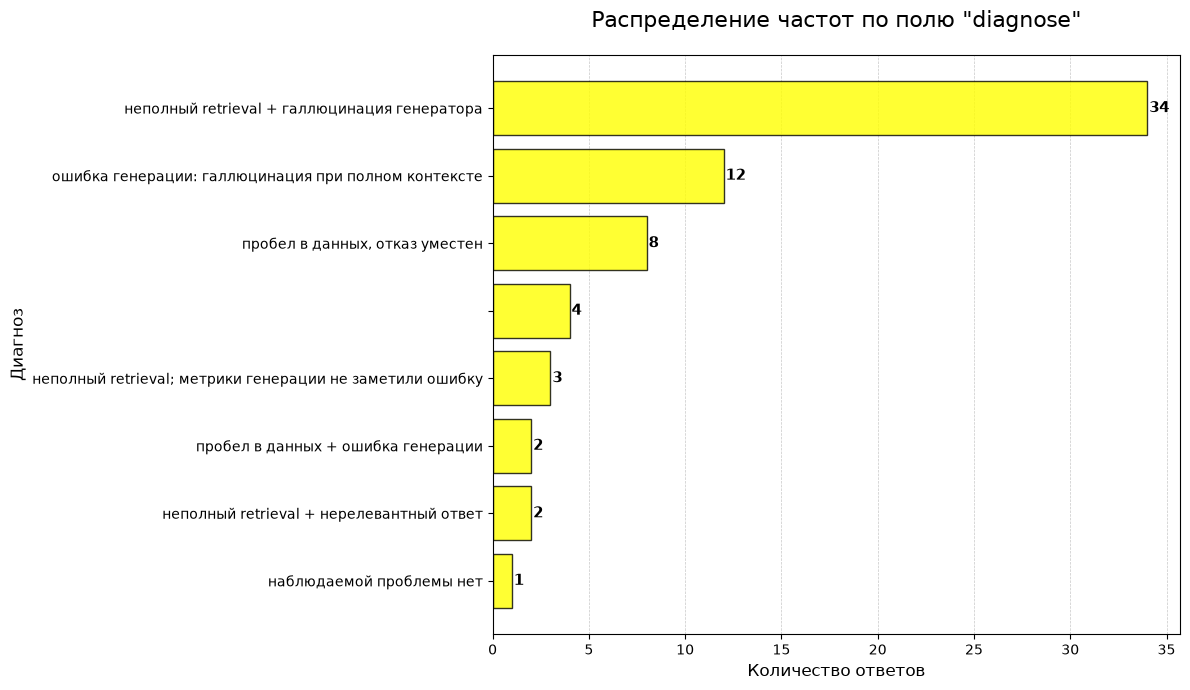

In [62]:
plot_diagnose(assessment_results)

# Выводы

Пайплайн страдает больше всего от низких retrieval метрик. Целевые метрики не были достигнуты, поэтому система не готова к пилоту.

Можно рассмотреть следующие способы улучшения:

1. Другую стратегию чанкинга (может быть семантический). Возможно чанки получились слишком большими и семантически размытыми.
2. Добавить в чанки заголовок документа в качестве якоря.
3. Использовать LLM для определения категории документа, соответствующей запросу, и потом уже фильтровать плотный поиск по категории.
4. Для решения проблем с галлюцинациями рассмотреть более тяжёлые модели для генерации.
5. Ответы модели часто слабо соответствуют эталонному ответу. Думаю, что это может быть улучшено так же как и предыдущий пункт введением более тяжелой модели, лучше обученной на русскоязычных корпусах.